In [85]:
# do not change line below
from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

In [86]:
def vortex_panel_method_0(x, y, v_inf=1.0, alpha=0.0, kutta=True):

    x = np.asarray(x, dtype=np.float64)         
    y = np.asarray(y, dtype=np.float64)         
    
    alpha = np.deg2rad(alpha)                  

    dx = np.diff(x)                             
    dy = np.diff(y)

    S = np.sqrt(dx**2 + dy**2)
    n = len(S)

    xc = 0.5*(x[:-1] + x[1:])
    yc = 0.5*(y[:-1] + y[1:]) 

    tx = dx/S
    ty = dy/S
    nx = dy/S
    ny = -dx/S


    vx = v_inf*np.cos(alpha)
    vy = v_inf*np.sin(alpha)


    q, w = np.polynomial.legendre.leggauss(16)


    A = np.zeros((n, n))

    for i in range(n):
        for j in range(n):

            if i==j:
                A[i, j] = 0.0
                continue

            s = 0.5*(q + 1.0) * S[j]
            xj = x[j] + (s / S[j])  * dx[j]
            yj = y[j] + (s / S[j])  * dy[j]

            rx = (xc[i] - xj)
            ry = (yc[i] - yj)
            r2 = rx**2 + ry**2

            u = -ry/(2*np.pi*r2)
            v = rx/(2*np.pi*r2)

            vn = u*nx[i] + v*ny[i]

            A[i, j] = 0.5*S[j]*np.sum(w*vn)

    b = -(vx*nx + vy*ny)

    if kutta:
        A[-1, :] = 0
        A[-1, 0] = 1
        A[-1, -1] = 1
    
    else:
        A[-1, :] = S

    b[-1] = 0

    γ = np.linalg.solve(A, b)

    Γ = np.sum(γ*S)    

    vt = γ
    Cp = 1.0 - (vt / v_inf)**2

    return {
        "gamma": γ,
        "vt": vt,
        "Cp": Cp,
        "circulation": Γ,
        "control_points": (xc, yc),
        "panel_lengths": S,
        "normals": (nx, ny),
        "influence_matrix": A
    }   

In [87]:
# generating circular Cylinder
def generate_cylinder(N, radius=1.0):
    theta = np.linspace(2*np.pi, 0, N)
    x = radius*np.cos(theta)
    y = radius*np.sin(theta)
    return x, y

In [88]:
# PART 1: Cp Distribution Comparison (N = 100 Panels)
N_test = 100
x_cyl, y_cyl = generate_cylinder(N_test)
res = vortex_panel_method_0(x_cyl, y_cyl, v_inf=1.0, alpha=0.0, kutta=False)

xc, yc = res["control_points"]
Cp_num = res["Cp"]

# Polar angles of control points mapped to [0, 2*pi]
theta_c = np.mod(np.arctan2(yc, xc), 2 * np.pi)
# Sort by angle for clean line plotting
sort_idx = np.argsort(theta_c)
theta_c = theta_c[sort_idx]
Cp_num = Cp_num[sort_idx]

# Analytical Cp
theta_exact = np.linspace(0, 2 * np.pi, 500)
Cp_exact_curve = 1.0 - 4.0 * (np.sin(theta_exact)**2)

In [89]:
# Grid Convergence
N_list = [16, 32, 64, 128, 256]

l2_errors = []
max_errors = []

for N in N_list:
    x_cyl, y_cyl = generate_cylinder(N)
    out = vortex_panel_method_0(x_cyl, y_cyl, v_inf=1.0, alpha=0.0, kutta=False)

    xc_i, yc_i = out["control_points"]
    theta_i = np.arctan2(yc_i, xc_i)

    Cp_exact_i = 1.0 - 4.0 * (np.sin(theta_i)**2)
    Cp_num_i = out["Cp"]

    # Exclude the last panel where tangency was replaced by circulation constraint
    err = np.abs(Cp_num_i[:-1] - Cp_exact_i[:-1])
    l2_errors.append(np.sqrt(np.mean(err**2)))
    max_errors.append(np.max(err))

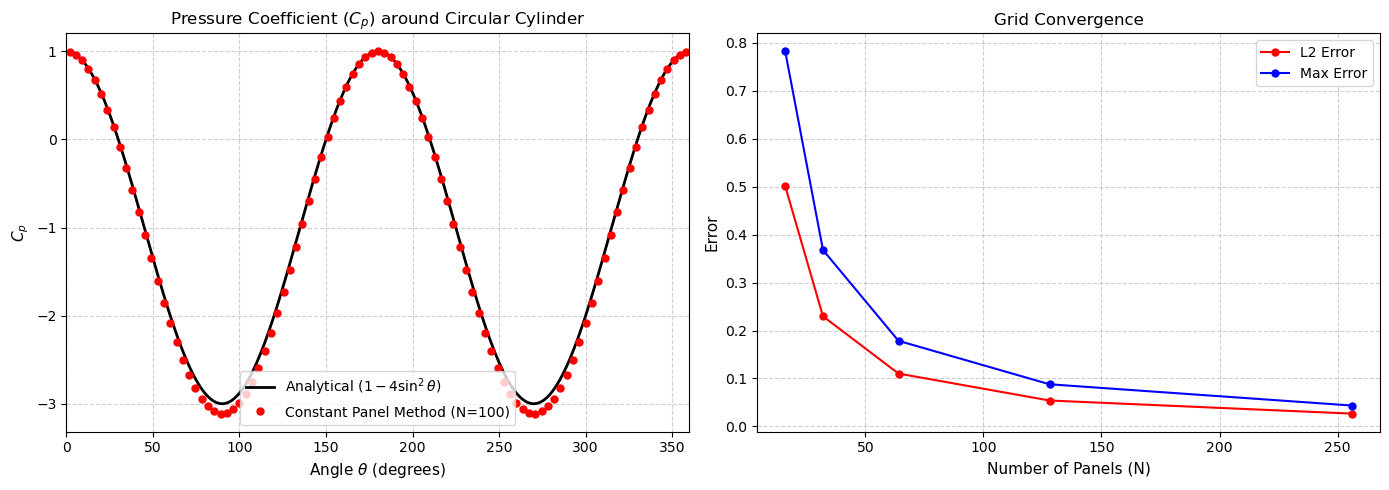

In [90]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].plot(np.rad2deg(theta_exact), Cp_exact_curve, 'k-', linewidth=2, label='Analytical ($1 - 4\\sin^2\\theta$)')
ax[0].plot(np.rad2deg(theta_c), Cp_num, 'ro', markersize=5, label=f'Constant Panel Method (N={N_test})')
ax[0].set_title('Pressure Coefficient ($C_p$) around Circular Cylinder', fontsize=12)
ax[0].set_xlabel('Angle $\\theta$ (degrees)', fontsize=11)
ax[0].set_ylabel('$C_p$', fontsize=11)
ax[0].set_xlim([0, 360])
ax[0].grid(True, linestyle='--', alpha=0.6)

ax[1].plot(N_list, l2_errors, 'ro-', markersize=5, label='L2 Error')
ax[1].plot(N_list, max_errors, 'bo-', markersize=5, label='Max Error')
ax[1].set_title('Grid Convergence', fontsize=12)
ax[1].set_xlabel('Number of Panels (N)', fontsize=11)
ax[1].set_ylabel('Error', fontsize=11)
ax[1].grid(True, linestyle='--', alpha=0.6)

ax[0].legend()
ax[1].legend()

plt.tight_layout()
plt.show()

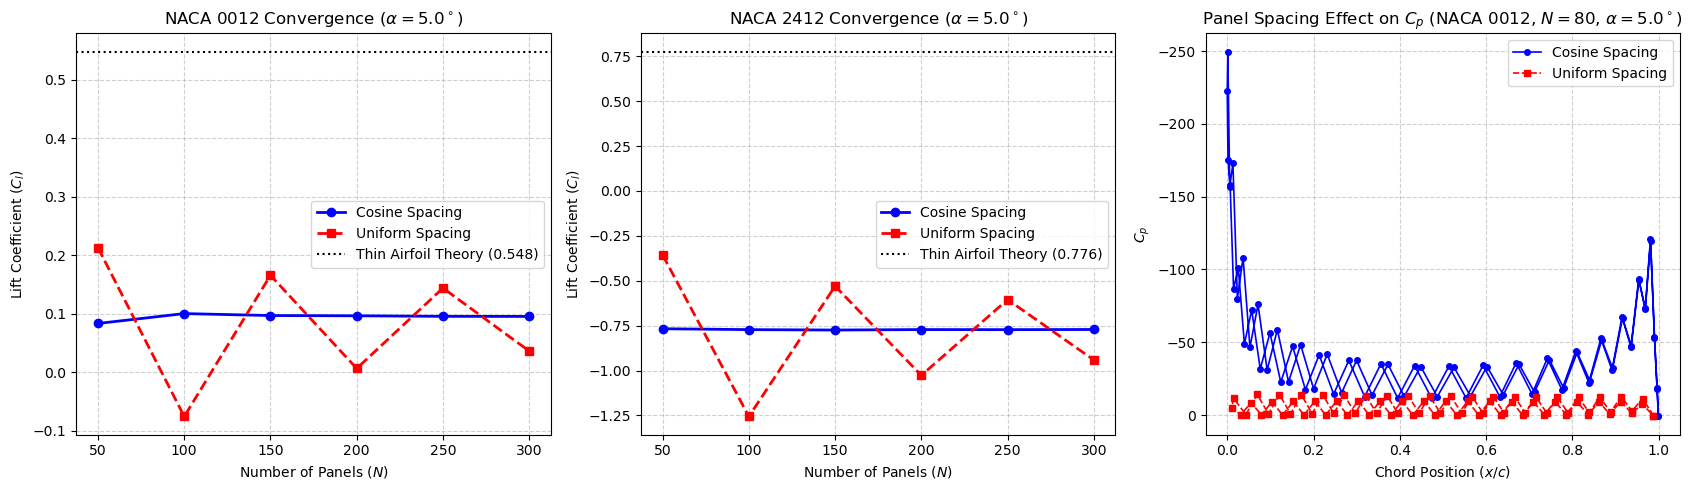

In [91]:
def generate_naca4(code="0012", n_panels=100, spacing="cosine"):
    """
    Generates closed trailing-edge NACA 4-digit airfoil coordinates in CLOCKWISE order:
    Trailing Edge -> Lower Surface -> Leading Edge -> Upper Surface -> Trailing Edge.
    Total nodes = n_panels + 1 (n_panels must be even).
    """
    m = int(code) / 100.0       # Maximum camber
    p = int(code) / 10.0        # Location of maximum camber
    t = int(code[2:]) / 100.0      # Maximum thickness

    n_half = n_panels // 2

    if spacing == "cosine":
        beta = np.linspace(0, np.pi, n_half + 1)
        xc = 0.5 * (1.0 - np.cos(beta))
    elif spacing == "uniform":
        xc = np.linspace(0.0, 1.0, n_half + 1)
    else:
        raise ValueError("spacing must be 'cosine' or 'uniform'")

    # Thickness distribution (closed trailing edge coefficient -0.1036)
    yt = 5.0 * t * (
        0.2969 * np.sqrt(xc)
        - 0.1260 * xc
        - 0.3516 * xc**2
        + 0.2843 * xc**3
        - 0.1036 * xc**4
    )

    # Mean camber line and slope
    yc = np.zeros_like(xc)
    dyc_dx = np.zeros_like(xc)

    if m > 0 and p > 0:
        idx1 = xc < p
        idx2 = xc >= p

        yc[idx1] = (m / p**2) * (2.0 * p * xc[idx1] - xc[idx1]**2)
        dyc_dx[idx1] = (2.0 * m / p**2) * (p - xc[idx1])

        yc[idx2] = (m / (1.0 - p)**2) * ((1.0 - 2.0 * p) + 2.0 * p * xc[idx2] - xc[idx2]**2)
        dyc_dx[idx2] = (2.0 * m / (1.0 - p)**2) * (p - xc[idx2])

    theta = np.arctan(dyc_dx)

    # Upper and lower surfaces
    xu = xc - yt * np.sin(theta)
    yu = yc + yt * np.cos(theta)
    xl = xc + yt * np.sin(theta)
    yl = yc - yt * np.cos(theta)

    # Assemble clockwise: TE -> Lower (reversed) -> LE -> Upper -> TE
    x = np.concatenate([xl[::-1], xu[1:]])
    y = np.concatenate([yl[::-1], yu[1:]])

    return x, y

# ==============================================================================
# SECTION 4: AIRFOIL CONVERGENCE & PANEL DISTRIBUTION STUDY
# ==============================================================================
panel_counts = [50, 100, 150, 200, 250, 300]
alpha_test = 5.0  # degrees

results = {
    "0012_cosine": [], "0012_uniform": [],
    "2412_cosine": [], "2412_uniform": []
}

for N in panel_counts:
    for airfoil in ["0012", "2412"]:
        for dist in ["cosine", "uniform"]:
            x_af, y_af = generate_naca4(airfoil, n_panels=N, spacing=dist)
            out = vortex_panel_method_0(x_af, y_af, v_inf=1.0, alpha=alpha_test, kutta=True)
            # Lift coefficient Cl = -2 * Gamma / (V_inf * c)
            Cl = -2.0 * out["circulation"] / 1.0
            results[f"{airfoil}_{dist}"].append(Cl)

# Thin airfoil theory reference values:
# NACA 0012: Cl = 2 * pi * alpha
Cl_tat_0012 = 2 * np.pi * np.deg2rad(alpha_test)
# NACA 2412: zero-lift angle alpha_L0 approx -2.07 deg -> Cl = 2 * pi * (alpha - alpha_L0)
Cl_tat_2412 = 2 * np.pi * np.deg2rad(alpha_test - (-2.077))

# ==============================================================================
# PLOTTING SECTION 4 RESULTS
# ==============================================================================
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# Plot 1: NACA 0012 Convergence (Cosine vs Uniform)
ax[0].plot(panel_counts, results["0012_cosine"], 'bo-', linewidth=2, label='Cosine Spacing')
ax[0].plot(panel_counts, results["0012_uniform"], 'rs--', linewidth=2, label='Uniform Spacing')
ax[0].axhline(Cl_tat_0012, color='k', linestyle=':', linewidth=1.5, label=f'Thin Airfoil Theory ({Cl_tat_0012:.3f})')
ax[0].set_title(f'NACA 0012 Convergence ($\\alpha = {alpha_test}^\\circ$)')
ax[0].set_xlabel('Number of Panels ($N$)')
ax[0].set_ylabel('Lift Coefficient ($C_l$)')
ax[0].grid(True, linestyle='--', alpha=0.6)
ax[0].legend()

# Plot 2: NACA 2412 Convergence (Cosine vs Uniform)
ax[1].plot(panel_counts, results["2412_cosine"], 'bo-', linewidth=2, label='Cosine Spacing')
ax[1].plot(panel_counts, results["2412_uniform"], 'rs--', linewidth=2, label='Uniform Spacing')
ax[1].axhline(Cl_tat_2412, color='k', linestyle=':', linewidth=1.5, label=f'Thin Airfoil Theory ({Cl_tat_2412:.3f})')
ax[1].set_title(f'NACA 2412 Convergence ($\\alpha = {alpha_test}^\\circ$)')
ax[1].set_xlabel('Number of Panels ($N$)')
ax[1].set_ylabel('Lift Coefficient ($C_l$)')
ax[1].grid(True, linestyle='--', alpha=0.6)
ax[1].legend()

# Plot 3: Effect of Panel Distribution on Leading-Edge Cp (N = 80, NACA 0012)
for dist, style in [("cosine", "bo-"), ("uniform", "rs--")]:
    x_af, y_af = generate_naca4("0012", n_panels=80, spacing=dist)
    out = vortex_panel_method_0(x_af, y_af, v_inf=1.0, alpha=alpha_test, kutta=True)
    xc, _ = out["control_points"]
    ax[2].plot(xc, out["Cp"], style, markersize=4, linewidth=1.2, label=f'{dist.capitalize()} Spacing')

ax[2].invert_yaxis()  # Standard aerodynamic convention: negative Cp at the top
ax[2].set_title(f'Panel Spacing Effect on $C_p$ (NACA 0012, $N=80$, $\\alpha={alpha_test}^\\circ$)')
ax[2].set_xlabel('Chord Position ($x/c$)')
ax[2].set_ylabel('$C_p$')
ax[2].grid(True, linestyle='--', alpha=0.6)
ax[2].legend()

plt.tight_layout()
plt.show()